# C++ backend speedup: SVD, neo-Hookean terms, and Hessian assembly

simkit ships an optional C++ core (`simkit._cpp`) behind the same flat functions
as the NumPy code. This notebook measures what it buys on one tetrahedral mesh:

1. **`svd_rv`** (the rotation-variant SVD behind the polar decomposition),
2. the **individual neo-Hookean terms**: `neo_hookean_gradient_element_F` and
   `neo_hookean_hessian_element_F` (per-element, no assembly),
3. the **assembled** gradient and Hessian (`neo_hookean_gradient_x`,
   `neo_hookean_hessian_x`) and their **subspace** equivalents
   (`elastic_gradient_z`, `elastic_hessian_z` with a dense reduced operator),
4. everything **together**: one full gradient + Hessian evaluation as a Newton
   step would issue it.

Each quantity is timed under `simkit.set_backend('python')` (NumPy only) and
`simkit.set_backend('cpp')`. The two backends are checked to agree before any
timing is reported.

In [1]:
import time
import warnings

import numpy as np
import scipy.sparse as sps

warnings.filterwarnings("ignore")

import simkit
from simkit.energies import elastic as E
from simkit.energies.neo_hookean import (
    neo_hookean_gradient_element_F,
    neo_hookean_hessian_element_F,
    neo_hookean_gradient_x,
    neo_hookean_hessian_x,
)
from simkit.svd_rv import svd_rv

print("simkit", simkit.__version__, "| C++ extension available:", simkit.cpp_available(),
      "| threads:", simkit.cpp_num_threads())
assert simkit.cpp_available(), "build the extension first: pip install -e ."
BACKENDS = ["python", "cpp"]

simkit 0.1.8 | C++ extension available: True | threads: 4


## Setup: a tetrahedral cube

A regular grid of `n^3` cubes split into 6 tets each. `n = 14` gives ~16k
tets, a typical size for an interactive 3D demo. Change `n` to scale.

In [2]:
def grid_tets(n):
    xs = np.linspace(0.0, 1.0, n + 1)
    X = np.array(np.meshgrid(xs, xs, xs, indexing="ij")).reshape(3, -1).T
    idx = np.arange((n + 1) ** 3).reshape(n + 1, n + 1, n + 1)
    c = idx[:-1, :-1, :-1].reshape(-1)
    dx, dy, dz = (n + 1) ** 2, (n + 1), 1
    v = [c, c + dx, c + dy, c + dx + dy, c + dz, c + dx + dz, c + dy + dz, c + dx + dy + dz]
    tets = [[0, 1, 3, 7], [0, 1, 5, 7], [0, 4, 5, 7], [0, 2, 3, 7], [0, 2, 6, 7], [0, 4, 6, 7]]
    T = np.concatenate([np.stack([v[i] for i in tet], axis=1) for tet in tets], axis=0)
    return X, T


n = 14
X, T = grid_tets(n)
rng = np.random.default_rng(0)
U = X + 0.005 * rng.standard_normal(X.shape)   # mild deformation, no inversions
t = T.shape[0]
mu = np.full((t, 1), 1.0)
lam = np.full((t, 1), 3.0)

simkit.set_backend("python")                    # precompute the operator once, with NumPy
J = simkit.deformation_jacobian(X, T)
vol = simkit.volume(X, T)
F = (J @ U.reshape(-1, 1)).reshape(-1, 3, 3)
print(f"{X.shape[0]} vertices, {t} tets, {J.shape[1]} dofs, J nnz = {J.nnz}")

3375 vertices, 16464 tets, 10125 dofs, J nnz = 356832


A reduced basis for the subspace tier: `r = 60` random orthonormal columns,
wrapped in the usual `ElasticEnergyZPrecomp` so `JB = J @ B` is dense.

In [3]:
r = 60
B, _ = np.linalg.qr(rng.standard_normal((J.shape[1], r)))
precomp = E.ElasticEnergyZPrecomp(B, X.reshape(-1, 1), sps.identity(J.shape[0]), J, 3)
z = 0.01 * rng.standard_normal((r, 1))
print("JB:", type(precomp.JB).__name__, precomp.JB.shape)

JB: ndarray (148176, 60)


## Timing helper

`best_of` returns the fastest of `repeat` runs, after one warm-up call, for
each backend. `compare` first asserts both backends return the same numbers.

In [4]:
def best_of(fn, repeat=5):
    fn()
    best = float("inf")
    for _ in range(repeat):
        t0 = time.perf_counter()
        fn()
        best = min(best, time.perf_counter() - t0)
    return best


def _as_dense(a):
    if isinstance(a, tuple):
        return np.concatenate([_as_dense(x) for x in a])
    if sps.issparse(a):
        return a.toarray().ravel()
    return np.asarray(a, dtype=float).ravel()


results = []


def compare(name, fn, repeat=5, atol=1e-9):
    out = {}
    for b in BACKENDS:
        simkit.set_backend(b)
        out[b] = fn()
    err = np.abs(_as_dense(out["python"]) - _as_dense(out["cpp"])).max()
    assert err < atol, f"{name}: backends disagree by {err}"
    times = {}
    for b in BACKENDS:
        simkit.set_backend(b)
        times[b] = best_of(fn, repeat)
    results.append((name, times["python"], times["cpp"], err))
    print(f"{name:42s} python {times['python']*1e3:8.1f} ms   cpp {times['cpp']*1e3:8.1f} ms   "
          f"speedup {times['python']/times['cpp']:5.1f}x   max|diff| {err:.1e}")
    return out

## 1. `svd_rv` on its own

The rotation-variant SVD of all 16k deformation gradients. NumPy's batched
`linalg.svd` goes through LAPACK; the C++ version runs a fixed-size 3x3
Jacobi SVD per element across threads. Only the recombined `U S V^T` and
`U V^T` are compared, since individual factors are unique only up to paired
sign flips.

In [5]:
_ = compare("svd_rv (U V^T, U S V^T)",
            lambda: (lambda U, S, V: (U @ V.transpose(0, 2, 1), U @ S @ V.transpose(0, 2, 1)))(*svd_rv(F)))

svd_rv (U V^T, U S V^T)                    python     63.0 ms   cpp      8.9 ms   speedup   7.1x   max|diff| 1.2e-14


## 2. Neo-Hookean terms individually

The element tier only: per-element first Piola-Kirchhoff stress (gradient
w.r.t. `F`) and the per-element 9x9 Hessian blocks. No quadrature weighting,
no PSD projection, no assembly.

In [6]:
_ = compare("neo_hookean_gradient_element_F", lambda: neo_hookean_gradient_element_F(F, mu, lam))
_ = compare("neo_hookean_hessian_element_F", lambda: neo_hookean_hessian_element_F(F, mu, lam))

neo_hookean_gradient_element_F             python      9.7 ms   cpp      0.3 ms   speedup  28.3x   max|diff| 3.6e-15


neo_hookean_hessian_element_F              python     24.6 ms   cpp      1.1 ms   speedup  23.1x   max|diff| 1.1e-14


The PSD projection that the assembled Hessian applies to every block is a
separate step, worth timing on its own because it is an eigendecomposition
per element.

In [7]:
simkit.set_backend("python")
He = neo_hookean_hessian_element_F(F, mu, lam) * vol.reshape(-1, 1, 1)
_ = compare("psd_project (16k blocks of 9x9)", lambda: simkit.psd_project(He))

psd_project (16k blocks of 9x9)            python    146.3 ms   cpp     22.0 ms   speedup   6.6x   max|diff| 3.0e-18


## 3. Assembled gradient and Hessian

`neo_hookean_gradient_x` does `F = J x`, the element stress, the `vol`
weighting and `J^T P`. `neo_hookean_hessian_x` additionally projects every
block to PSD and assembles `J^T blockdiag(He) J`. Under the C++ backend the
whole chain runs in one call (CSR in, CSR out).

In [8]:
_ = compare("neo_hookean_gradient_x (assembled)", lambda: neo_hookean_gradient_x(U, J, mu, lam, vol))
_ = compare("neo_hookean_hessian_x (assembled)", lambda: neo_hookean_hessian_x(U, J, mu, lam, vol), atol=1e-8)

neo_hookean_gradient_x (assembled)         python     10.5 ms   cpp      1.5 ms   speedup   6.9x   max|diff| 7.0e-18


neo_hookean_hessian_x (assembled)          python    324.5 ms   cpp     64.3 ms   speedup   5.0x   max|diff| 1.8e-15


The assembly step alone, isolated from the element kernels:

In [9]:
simkit.set_backend("python")
He_psd = simkit.psd_project(He)
_ = compare("block_diag_sandwich J^T blkdiag(He) J", lambda: simkit.block_diag_sandwich(J, He_psd), atol=1e-8)

block_diag_sandwich J^T blkdiag(He) J      python    154.4 ms   cpp     31.0 ms   speedup   5.0x   max|diff| 5.6e-16


### Subspace equivalents

With a dense reduced operator `JB` of shape `(t*9, r)`, the gradient is
`JB^T P` and the Hessian is the dense `r x r` matrix `JB^T blockdiag(He) JB`.

In [10]:
_ = compare("elastic_gradient_z (subspace, r=60)",
            lambda: E.elastic_gradient_z(z, mu, lam, vol, "neo-hookean", precomp))
_ = compare("elastic_hessian_z (subspace, r=60)",
            lambda: E.elastic_hessian_z(z, mu, lam, vol, "neo-hookean", precomp), atol=1e-8)

elastic_gradient_z (subspace, r=60)        python     13.6 ms   cpp     15.3 ms   speedup   0.9x   max|diff| 5.1e-17


elastic_hessian_z (subspace, r=60)         python    364.7 ms   cpp     70.7 ms   speedup   5.2x   max|diff| 1.0e-15


## 4. Everything together

One evaluation of gradient **and** Hessian, as a Newton step issues it, in
full space and in the subspace. The C++ column is the end-to-end time a
simulation loop sees per iteration (the linear solve excluded).

In [11]:
_ = compare("full space: gradient + hessian",
            lambda: (neo_hookean_gradient_x(U, J, mu, lam, vol), neo_hookean_hessian_x(U, J, mu, lam, vol)), atol=1e-8)
_ = compare("subspace: gradient + hessian (r=60)",
            lambda: (E.elastic_gradient_z(z, mu, lam, vol, "neo-hookean", precomp),
                     E.elastic_hessian_z(z, mu, lam, vol, "neo-hookean", precomp)), atol=1e-8)

full space: gradient + hessian             python    343.1 ms   cpp     54.0 ms   speedup   6.3x   max|diff| 1.8e-15


subspace: gradient + hessian (r=60)        python    380.5 ms   cpp     81.2 ms   speedup   4.7x   max|diff| 1.0e-15


## Summary

In [12]:
print(f"{'quantity':42s}{'python':>12s}{'cpp':>12s}{'speedup':>10s}")
print("-" * 76)
for name, tp, tc, err in results:
    print(f"{name:42s}{tp*1e3:10.1f}ms{tc*1e3:10.1f}ms{tp/tc:9.1f}x")

quantity                                        python         cpp   speedup
----------------------------------------------------------------------------
svd_rv (U V^T, U S V^T)                         63.0ms       8.9ms      7.1x
neo_hookean_gradient_element_F                   9.7ms       0.3ms     28.3x
neo_hookean_hessian_element_F                   24.6ms       1.1ms     23.1x
psd_project (16k blocks of 9x9)                146.3ms      22.0ms      6.6x
neo_hookean_gradient_x (assembled)              10.5ms       1.5ms      6.9x
neo_hookean_hessian_x (assembled)              324.5ms      64.3ms      5.0x
block_diag_sandwich J^T blkdiag(He) J          154.4ms      31.0ms      5.0x
elastic_gradient_z (subspace, r=60)             13.6ms      15.3ms      0.9x
elastic_hessian_z (subspace, r=60)             364.7ms      70.7ms      5.2x
full space: gradient + hessian                 343.1ms      54.0ms      6.3x
subspace: gradient + hessian (r=60)            380.5ms      81.2ms      4.7x

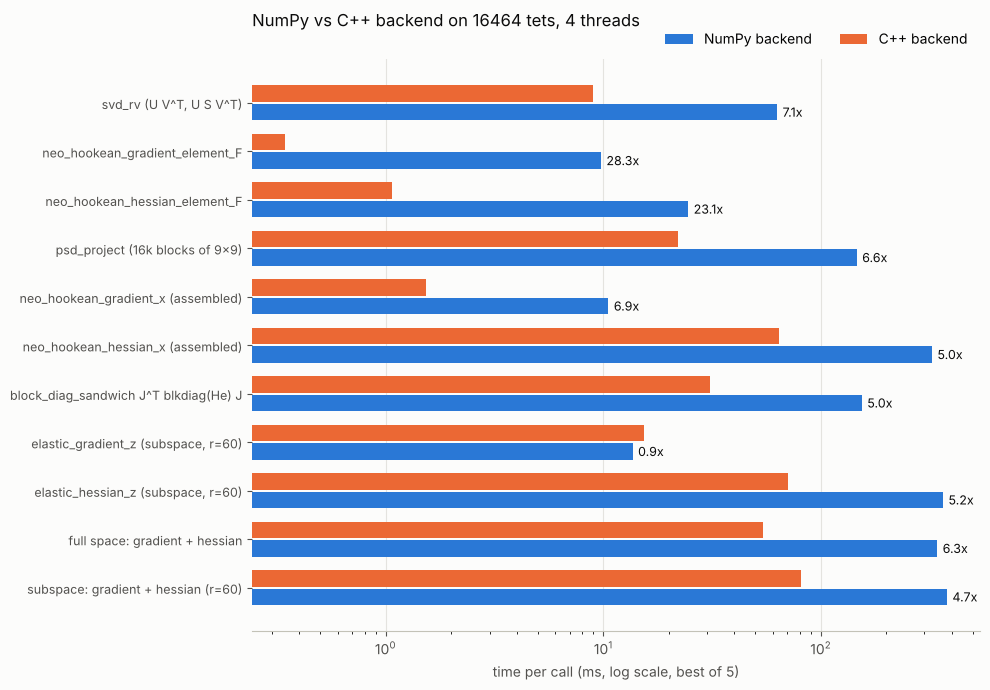

In [13]:
import matplotlib.pyplot as plt

names = [r[0] for r in results]
py_ms = np.array([r[1] for r in results]) * 1e3
cpp_ms = np.array([r[2] for r in results]) * 1e3
speedup = py_ms / cpp_ms

# Reference categorical palette: slot 1 (blue) for NumPy, slot 2 (orange) for C++.
SURFACE, INK, MUTED = "#fcfcfb", "#0b0b0b", "#52514e"
C_PY, C_CPP = "#2a78d6", "#eb6834"

y = np.arange(len(names))
h = 0.38
fig, ax = plt.subplots(figsize=(10, 0.5 * len(names) + 1.5), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
ax.barh(y + h / 2, py_ms, height=h - 0.04, color=C_PY, label="NumPy backend", linewidth=0)
ax.barh(y - h / 2, cpp_ms, height=h - 0.04, color=C_CPP, label="C++ backend", linewidth=0)
for yi, s, tp in zip(y, speedup, py_ms):
    ax.text(tp * 1.06, yi + h / 2, f"{s:.1f}x", va="center", ha="left", fontsize=9, color=INK)
ax.set_yticks(y)
ax.set_yticklabels(names, fontsize=9, color=INK)
ax.invert_yaxis()
ax.set_xscale("log")
ax.set_xlabel("time per call (ms, log scale, best of 5)", color=MUTED)
ax.set_title(f"NumPy vs C++ backend on {t} tets, {simkit.cpp_num_threads()} threads", loc="left", color=INK, pad=24)
ax.grid(axis="x", color="#e4e3df", linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color("#c3c2b7")
ax.tick_params(colors=MUTED)
ax.legend(frameon=False, loc="lower right", bbox_to_anchor=(1.0, 1.0), ncol=2)
plt.tight_layout()
plt.show()

## Reading the numbers

- **SVD and the element kernels** are where the C++ port gains the most: the
  NumPy versions pay for broadcasting temporaries and generic LAPACK calls,
  while the C++ loop works on fixed-size 3x3 and 9x9 blocks across threads.
- **The assembled Hessian** is dominated by the per-element PSD projection
  (one 9x9 eigendecomposition per element) and the sparse assembly. Both are
  in C++ now, so the end-to-end call is several times faster even though the
  CSR result still has to be built. Analytic eigensystems for the material
  would be the next step if this term needs to go further.
- **The subspace tier** is already cheap in NumPy because the heavy product
  `JB^T blockdiag(He) JB` is a dense BLAS call; the C++ path mostly removes the
  element-kernel and projection overhead around it.
- **Together** the full-space gradient + Hessian pair drops from hundreds of
  milliseconds to tens, which is the per-iteration budget a Newton solver sees.

Re-run with a larger `n` to see how the gap scales; the C++ side is linear in
the number of elements and uses `simkit.cpp_num_threads()` worker threads.